<a href="https://colab.research.google.com/github/vitoriaayres/diario_secreto/blob/main/CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

In [8]:
device= torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('USANDO DEVICE: ', device)

transform= transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5,))
])
trainset= torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
testset= torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
classes= ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship','truck' )
print(f'SAMPLES DE TREINAMENTO: {len(trainset)} | SAMPLE DE TESTES: {len(testset)}')

USANDO DEVICE:  cpu
SAMPLES DE TREINAMENTO: 50000 | SAMPLE DE TESTES: 10000


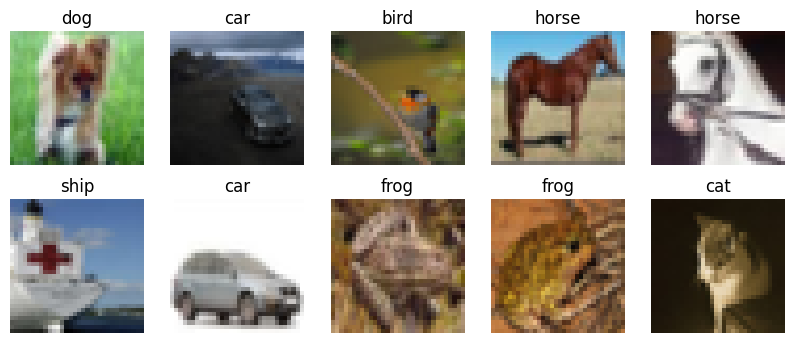

In [9]:
def imshow(img):
  img= img / 2 + 0.5
  plt.imshow(img.permute(1,2,0))
  plt.axis('off')
images, labels= next(iter(torch.utils.data.DataLoader(trainset, batch_size=10, shuffle=True)))
plt.figure(figsize=(10,4))
for i in range(10):
  plt.subplot(2,5,i+1)
  imshow(images[i])
  plt.title(classes[labels[i]])
plt.show()

In [11]:
BATCH_SIZE= 64
trainloader = torch.utils.data.DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True)
testloader  = torch.utils.data.DataLoader(testset,  batch_size=BATCH_SIZE, shuffle=False)

for images, labels in trainloader:
  print('FORMATO DO BATCH:  ', images.shape, 'LABELS: ', labels.shape)
  break

FORMATO DO BATCH:   torch.Size([64, 3, 32, 32]) LABELS:  torch.Size([64])


In [12]:
class CNN(nn.Module):
  def __init__(self):
    super().__init__()
    self.conv1= nn.Conv2d(3, 16, kernel_size=3, padding=1)
    self.bn1= nn.BatchNorm2d(16)
    self.conv2= nn.Conv2d(16, 32, kernel_size=3, padding=1)
    self.bn2= nn.BatchNorm2d(32)
    self.conv3= nn.Conv2d(32, 64, kernel_size=3, padding=1)
    self.bn3= nn.BatchNorm2d(64)
    self.pool= nn.MaxPool2d(2, 2)
    self.fc1= nn.Linear(64 * 4 * 4, 128)
    self.fc2= nn.Linear(128, 10)
    self.relu= nn.ReLU()
    self.dropout= nn.Dropout(0.2)
  def forward(self, x):
    x= self.pool(self.relu(self.bn1(self.conv1(x))))
    x= self.pool(self.relu(self.bn2(self.conv2(x))))
    x= self.pool(self.relu(self.bn3(self.conv3(x))))
    x= x.view(x.size(0), -1)
    x= self.relu(self.fc1(x))
    x= self.fc2(x)
    return x

In [15]:
model= CNN().to(device)
total= sum(p.numel() for p in model.parameters())
trainable= sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'PARAMETROS TOTAL: {total:,} | TREINAVEIS: {trainable:,}')

x= torch.randn(1, 3, 32, 32).to(device)
out= model(x)
print('OUTPUT PARA 1 IMAGEM: ', out.shape)

PARAMETROS TOTAL: 156,298 | TREINAVEIS: 156,298
OUTPUT PARA 1 IMAGEM:  torch.Size([1, 10])


In [16]:
criterion= nn.CrossEntropyLoss()
optimizer= optim.Adam(model.parameters(), lr=1e-3)

In [20]:
EPOCHS = 10
train_losses, val_accs = [], []

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    for images, labels in trainloader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    avg_loss = running_loss / len(trainloader)
    train_losses.append(avg_loss)

    model.eval()
    correct = total = 0
    with torch.no_grad():
        for images, labels in testloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    acc = 100 * correct / total
    val_accs.append(acc)
    print(f"Epoch {epoch+1}/{EPOCHS} | loss: {avg_loss:.4f} | val acc: {acc:.2f}%")

Epoch 1/10 | loss: 0.6712 | val acc: 73.13%
Epoch 2/10 | loss: 0.6036 | val acc: 74.07%
Epoch 3/10 | loss: 0.5500 | val acc: 73.38%
Epoch 4/10 | loss: 0.5069 | val acc: 76.49%
Epoch 5/10 | loss: 0.4620 | val acc: 75.41%
Epoch 6/10 | loss: 0.4234 | val acc: 75.04%
Epoch 7/10 | loss: 0.3866 | val acc: 75.72%
Epoch 8/10 | loss: 0.3512 | val acc: 74.83%
Epoch 9/10 | loss: 0.3300 | val acc: 75.22%
Epoch 10/10 | loss: 0.2969 | val acc: 75.08%


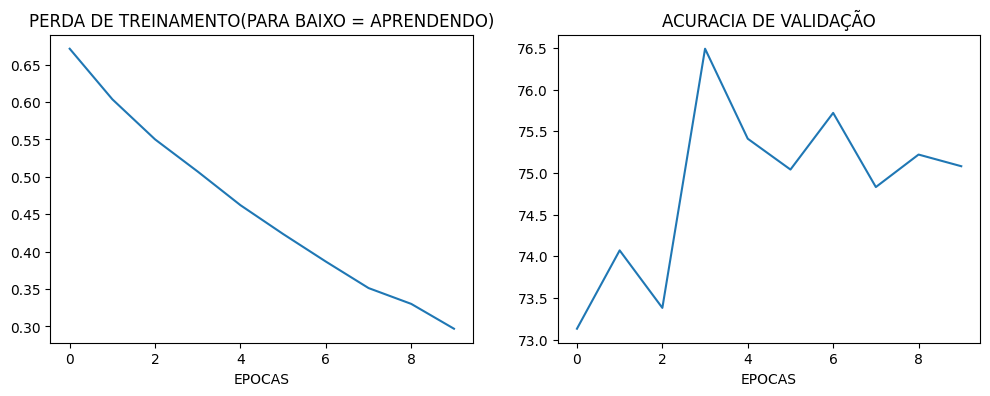

In [21]:
fig, axes= plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(train_losses)
axes[0].set_title('PERDA DE TREINAMENTO(PARA BAIXO = APRENDENDO)')
axes[0].set_xlabel('EPOCAS')
axes[1].plot(val_accs)
axes[1].set_title('ACURACIA DE VALIDAÇÃO')
axes[1].set_xlabel('EPOCAS')
plt.show()

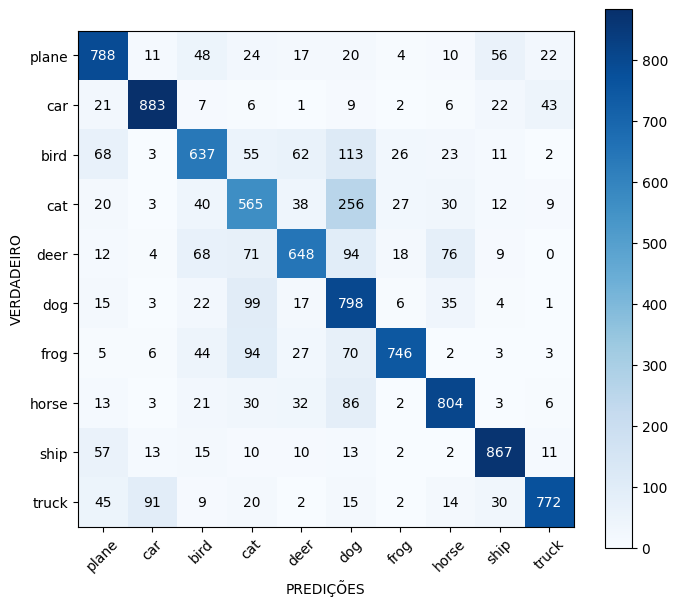

In [22]:
model.eval()
confusion= torch.zeros(10, 10, dtype=torch.int32)
with torch.no_grad():
  for images, labels in testloader:
    outputs= model(images.to(device)).cpu()
    preds= torch.argmax(outputs, dim=1)
    for t, p in zip(labels, preds):
      confusion[t,p] += 1
plt.figure(figsize=(8, 7))
plt.imshow(confusion.numpy(), cmap='Blues')
plt.colorbar()
plt.xticks(range(10), classes, rotation=45)
plt.yticks(range(10), classes)
plt.xlabel('PREDIÇÕES')
plt.ylabel('VERDADEIRO')
for i in range(10):
  for j in range(10):
    plt.text(j, i, int(confusion[i, j]), ha='center', va='center',
           color='white' if confusion[i, j] > confusion.max()/2 else 'black')
plt.show()

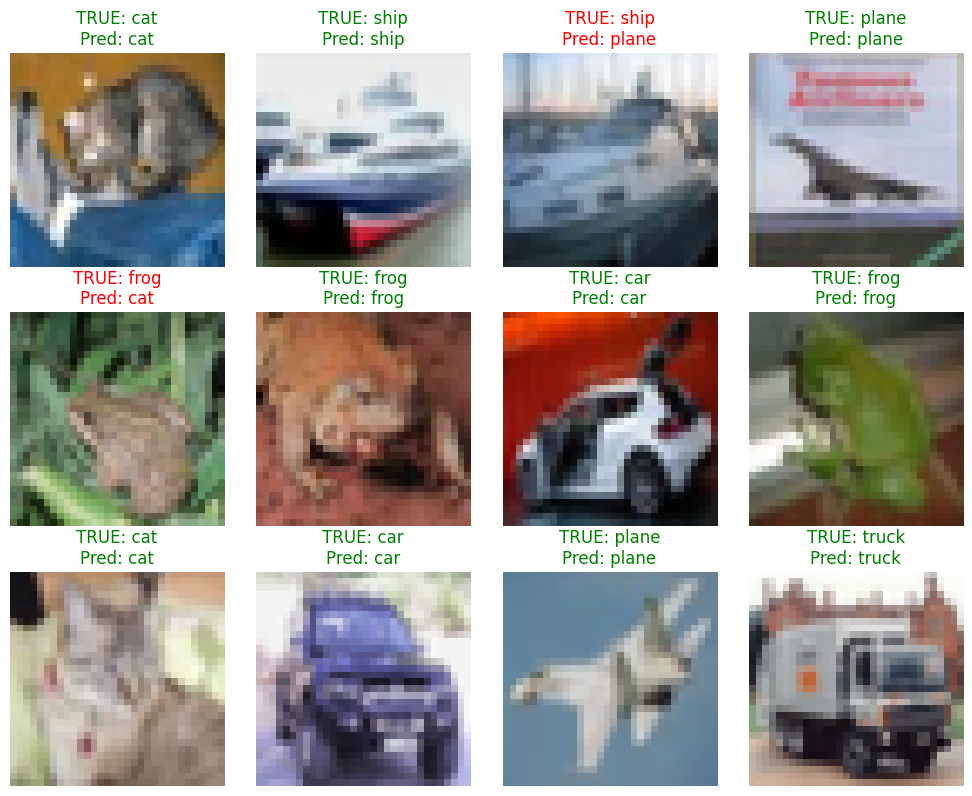

In [26]:
def visualize_predictions(n=12):
  images, labels= next(iter(testloader))
  images, labels= images[:n], labels[:n]
  model.eval()
  with torch.no_grad():
    outputs= model(images.to(device)).cpu()
  preds= torch.argmax(outputs, dim=1)

  fig, axes= plt.subplots(3, 4, figsize=(10, 8))
  for i, ax in enumerate(axes.flat):
    ax.imshow((images[i]/2 + 0.5).permute(1, 2, 0).numpy())
    ax.set_title(f'TRUE: {classes[labels[i]]}\nPred: {classes[preds[i]]}',
                 color='green' if preds[i] == labels[i] else 'red')
    ax.axis('off')
  plt.tight_layout()
  plt.show()
visualize_predictions()

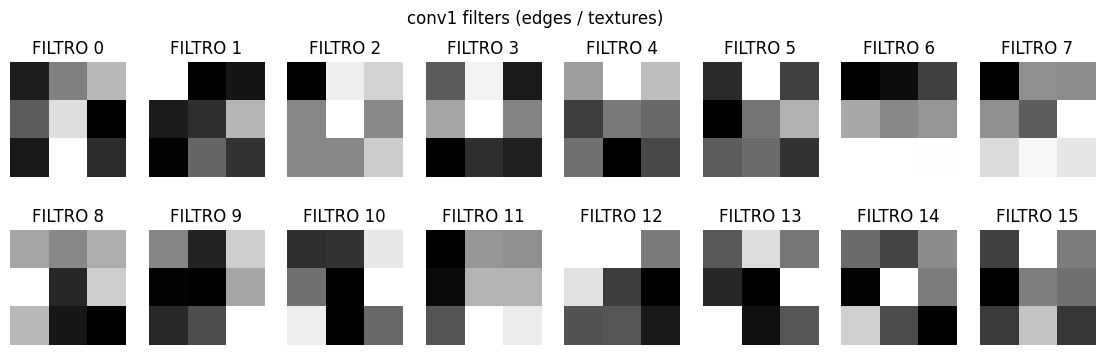

In [29]:
def visualize_filter(n=16):
  filters= model.conv1.weight.data.cpu().numpy()
  fig, axes= plt.subplots(2, 8, figsize=(14, 4))
  for i, ax in enumerate(axes.flat):
    ax.imshow(filters[i,0], cmap='gray')
    ax.set_title(f'FILTRO {i}')
    ax.axis('OFF')
  plt.suptitle('conv1 filters (edges / textures)')
  plt.show()
visualize_filter()

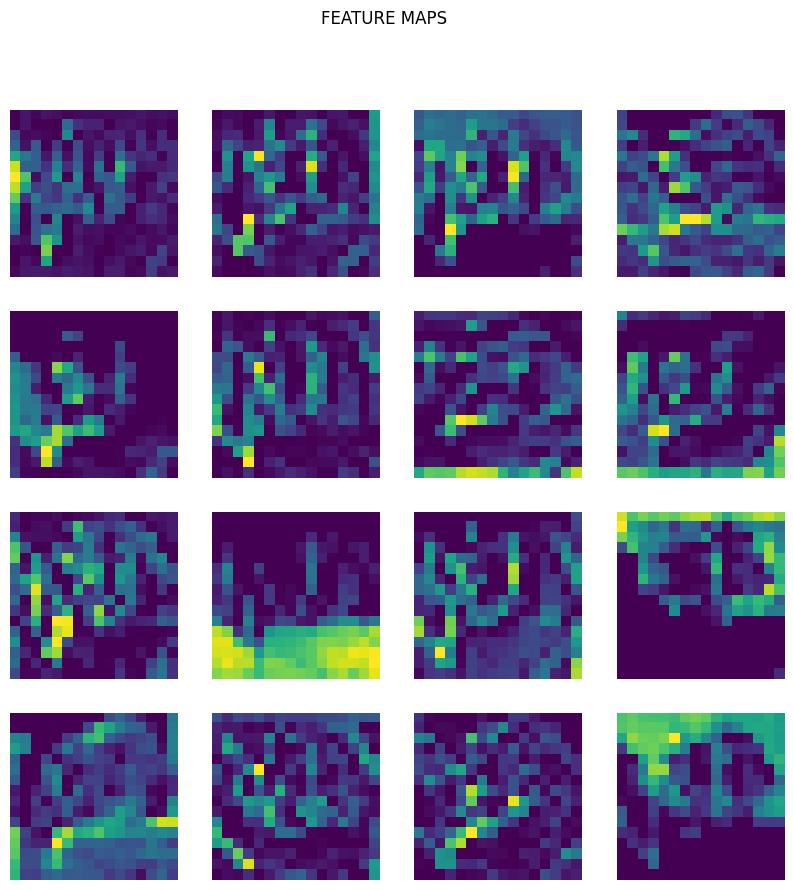

In [30]:
def visualize_feature_maps(image, n=16):
  model.eval()
  with torch.no_grad():
    x= model.pool(model.relu(model.bn1(model.conv1(image.unsqueeze(0).to(device)))))
  x= x.cpu().squeeze(0)
  fig, axes= plt.subplots(4,4,figsize=(10,10))
  for i, ax in enumerate(axes.flat):
    ax.imshow(x[i].numpy(), cmap='viridis')
    ax.axis('off')
  plt.suptitle('FEATURE MAPS')
  plt.show()
images, _= next(iter(testloader))
visualize_feature_maps(images[0])